<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/assingments/assingment_4/MINE_4210_ADL_202620_T4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)


# **Taller 4: Modelos generativos para imágenes de células sanguíneas**

### **Contexto y Objetivos**

En el laboratorio clínico el recuento diferencial de células en un frotis de sangre periférica orienta el diagnóstico de infecciones, anemias y enfermedades hematológicas. Hacerlo manualmente toma tiempo y sus resultados varían entre observadores, por lo que muchos laboratorios utilizan clasificadores automáticos de imágenes.

Un laboratorio de hematología de un hospital quiere entrenar su propio clasificador, pero tiene solo 200 imágenes de basófilos, una célula poco frecuente en las muestras. Un miembro del equipo propone usar modelos generativos para producir imágenes sintéticas de basófilos, con el fin de complementar los datos de entrenamiento. Esto permitiría, además, compartir imágenes sintéticas en lugar de las reales con otras instituciones, para proteger la información de los pacientes. Antes de decidir, se quiere hacer una evaluación técnica que permita responder a tres inquietudes: ¿las imágenes generadas son realistas y variadas?, ¿el modelo reproduce imágenes reales de pacientes? ¿las imágenes sintéticas mejoran el clasificador?

En este taller compararán un VAE y un modelo de difusión para generar imágenes de basófilos, y evaluarán si las imágenes sintéticas mejoran un clasificador.

Conjunto de datos. Se utilizará BloodMNIST  (https://medmnist.com/). Este dataset está compuesto por 17.092 imágenes de células de sangre periférica, en color y de 28×28 píxeles, clasificadas en 8 tipos (0: basófilo, 1: eosinófilo, 2: eritroblasto, 3: granulocito inmaduro, 4: linfocito, 5: monocito, 6: neutrófilo, 7: plaqueta). Las imágenes originales se adquirieron en el Hospital Clínic de Barcelona, a partir de personas sin infecciones, enfermedades hematológicas u oncológicas, ni tratamiento farmacológico.

Debido al protocolo de recolección de las imágenes, los basófilos representan cerca del 7 % del conjunto, una proporción superior a la práctica clínica. Para simular la situación real del laboratorio, entrenarán los generadores únicamente con 200 basófilos de la partición oficial de entrenamiento. Seleccionen el subconjunto de la siguiente forma:

```python
import numpy as np
from medmnist import BloodMNIST

train = BloodMNIST(split="train", download=True)
val   = BloodMNIST(split="val",   download=True)
test  = BloodMNIST(split="test",  download=True)

idx_baso = np.where(train.labels.ravel() == 0)[0]
rng = np.random.default_rng(42)
idx_sub = rng.choice(idx_baso, size=200, replace=False)
basofilos_train = train.imgs[idx_sub]   # (200, 28, 28, 3)
```

Llamaremos N al número total de basófilos en la partición de entrenamiento. El subconjunto de 200 forma parte de ellos. Para los modelos generativos, normalicen los píxeles al rango [−1, 1]. El conjunto se usa con fines académicos, y los resultados no deben interpretarse como evidencia sobre la utilidad clínica de los modelos. Con base en el tipo de licencia de este conjunto de imágenes deben hacer la citación que corresponde.

<br>

**Actividades**

**1. Exploración y clasificador de referencia.**

- Revisen la distribución de clases en entrenamiento, validación y prueba, y reporten N.
- Muestren seis imágenes reales por clase. ¿Qué distingue visualmente a los basófilos y con cuáles podrían confundirse?
- Construyan un conjunto de entrenamiento que contenga únicamente los 200 basófilos seleccionados y todas las imágenes de entrenamiento de las otras siete clases. Entrenen una CNN con este conjunto, utilizando la siguiente arquitectura:
  ```python
  Conv2D(32, 3×3, ReLU) + MaxPooling(2×2)
  Conv2D(64, 3×3, ReLU) + MaxPooling(2×2)
  Flatten + Dense(128, ReLU) + Dropout(0.3)
  Dense(8, softmax)
  ```
Utilicen Adam (learning rate = 1e-3), máximo 10 épocas y EarlyStopping sobre val_loss (patience=3, restaurando los mejores pesos). Reporten, en el conjunto de test, el F1 macro, y el F1_score y el recall de la clase basófilo.

Conserven el clasificador entrenado y sus resultados, ya que se utilizarán como referencia para evaluar las imágenes generadas y determinar, en la actividad 4, si el aumento sintético mejora la clasificación.

<br>

**2. Generación de imágenes con VAE y DDPM.**

Entrenen ambos modelos exclusivamente con los mismos 200 basófilos. Pueden partir de los ejemplos del laboratorio demostrativo (Laboratorio 10).

**2.1. Modelo 1. VAE**

- Encoder y decoder convolucionales (28 → 14 → 7 y reconstrucción hasta 28 × 28), adaptados a tres canales RGB.
- Espacio latente de dimensión 16; pérdida de reconstrucción más divergencia KL. Documenten su implementación.
- Máximo 300 épocas o 20 minutos de GPU, lo que ocurra primero. Presenten la evolución de las pérdidas.

**2.2 Modelo 2. Modelo de difusión (DDPM)**

Implementen un modelo de difusión utilizando la librería diffusers de Hugging Face. Utilicen la siguiente configuración:

- Arquitectura: UNet2DModel, adaptada a imágenes RGB de 28 × 28 píxeles.
- Proceso de difusión: DDPMScheduler con 1000 pasos de entrenamiento.
- Función de pérdida: error cuadrático medio entre el ruido añadido a las imágenes y el ruido predicho por la U-Net.
- Optimizador: AdamW, con tasa de aprendizaje 1e-4 y tamaño de lote máximo de 64.
- Entrenamiento: máximo de 60 minutos de GPU.

Registren la evolución de la pérdida y documenten la arquitectura utilizada, el número de actualizaciones de los parámetros y el tiempo de entrenamiento.

No se exige alcanzar una calidad visual específica. Si las imágenes tienen defectos, analícenlos y discútanlos. Los 1000 pasos del scheduler describen el proceso de difusión y no equivalen a 1000 actualizaciones de parámetros.

**2.3 Generación**

Generen 300 imágenes sintéticas con cada modelo. Para DDPM indiquen el número de pasos de inferencia utilizado. Conserven los modelos y las imágenes para las actividades siguientes.

<br>

**3. Evaluación de las imágenes generadas**.

| Aspecto | Evaluación |
|-|-|
| Calidad visual y consistencia con la clase | Muestren 16 imágenes por generador y 16 basófilos reales del conjunto de test. Calculen el porcentaje de las 300 sintéticas clasificadas como basófilos por la CNN <br> y compárenlo con su recall sobre basófilos reales de test. | Distribución de longitudes en tokens, distribución de clases y análisis de longitud por ODS. |
| Diversidad | Distancia euclidiana promedio entre pares de 100 imágenes sintéticas por modelo y 100 basófilos reales de test, complementada con inspección visual. |
| Posible memorización | Para cada imagen sintética, busquen el vecino más cercano entre los 200 basófilos de entrenamiento. Muestren los cinco pares más similares por modelo <br> y comparen sus distancias con las de basófilos reales de test frente a esos mismos 200 ejemplos. |

Antes de calcular distancias, lleven las imágenes reales y las sintéticas a la misma escala de valores (por ejemplo, [0, 1]). Con base en estos resultados, elijan el generador que usarán para el aumento sintético y justifiquen la decisión.

<br>

**4. Evaluaciones en el clasificador**. En la actividad 1 entrenaron una CNN utilizando 200 basófilos reales y todas las imágenes de las otras siete clases. Ahora evaluarán si incorporar imágenes sintéticas permite mejorar su desempeño. Para ello:

- Para la construcción de un clasificador con sobre muestreo. Preparen un conjunto de entrenamiento con todas las imágenes de las otras siete clases utilizadas en la actividad 1 y los 200 basófilos reales repetidos hasta completar N (por ejemplo, con np.resize(idx_sub, N)).
- Para la construcción de un clasificador con aumento sintético. Preparen un conjunto de entrenamiento con los 200 basófilos reales, todas las imágenes de las otras siete clases y (N − 200) imágenes sintéticas producidas por el generador seleccionado en la actividad 3, hasta completar N basófilos. Si necesitan más de las 300 imágenes generadas inicialmente, produzcan las adicionales con el mismo modelo. Apliquen a las imágenes sintéticas el mismo formato y preprocesamiento utilizado para entrenar la CNN.
- Entrenen una CNN con cada conjunto, utilizando la misma arquitectura, configuración de entrenamiento y semilla de la actividad 1.
- Evalúen ambas CNN sobre la misma partición oficial de test utilizada en la actividad 1. Presenten en una tabla el F1 macro, y el F1_score y el recall de la clase basófilo de los tres clasificadores (referencia, sobre muestreo y aumento sintético), junto con sus matrices de confusión.

<br>

**5. Análisis**. A partir de los resultados obtenidos, respondan las siguientes preguntas:

1. Comparación de los modelos generativos. ¿Qué diferencias encuentran entre el VAE y el DDPM en términos de calidad visual, diversidad, posible memorización  y costo de generación? ¿Cómo se relacionan estas diferencias con el funcionamiento de ambos modelos? ¿Qué limitaciones tienen las métricas utilizadas para evaluar las imágenes, considerando además que la CNN evaluadora se entrenó con los mismos 200 basófilos que usaron los generadores?
2. Utilidad de las imágenes sintéticas. ¿La incorporación de imágenes sintéticas mejoró el desempeño del clasificador frente al entrenado únicamente con imágenes reales y, sobre todo, frente al entrenado con sobre muestreo? ¿Qué relación encuentran entre los resultados de clasificación y la calidad y diversidad de las imágenes generadas? Dado que cada clasificador se entrenó con una sola semilla, ¿qué tan confiables son las diferencias observadas? ¿Qué limitaciones tiene este experimento para determinar si las imágenes sintéticas aportan información nueva?
3. Recomendación al laboratorio. En una nota de máximo 300 palabras, indiquen si recomiendan utilizar imágenes sintéticas para complementar los datos de entrenamiento y si consideran adecuado compartirlas con otras instituciones en lugar de las imágenes reales. Justifiquen sus recomendaciones con base en los resultados obtenidos y señalen las limitaciones y la evidencia adicional que sería necesaria antes de aplicar estas soluciones en un entorno clínico.

**Bono (hasta 15 % adicional).** A partir del código del laboratorio, entrenen una GAN con los mismos 200 basófilos (Adam, learning rate 2e-4, betas=(0.5, 0.999), máximo 20 minutos de GPU). Generen 300 imágenes y comparen calidad visual, consistencia con la clase y diversidad con VAE y DDPM mediante los procedimientos correspondientes de la actividad 3. ¿Hay indicios de colapso de modos? ¿Qué evidencia los respalda? ¿Cambiarían la elección del generador?

### **Entregable**

Notebook (.ipynb) con todas las celdas ejecutadas, organizado por actividades, que incluya código, tablas, visualizaciones, análisis, nota al laboratorio,  referencias a recursos externos y con todas las indicaciones anteriormente estipuladas en la sección de laboratorios en **Bloque Neón**. Documenten decisiones y permitan reproducir los experimentos en la medida de lo posible.



### **Rúbrica**

| Criterio | Peso | Qué se evalúa |
|-|-|-|
| 1. Exploración y clasificador de referencia | 15 % | Exploración y distribución de clases, selección de los 200 basófilos, entrenamiento de la CNN y evaluación mediante las métricas solicitadas. |
| 2. Generación de imágenes con VAE y DDPM | 30 % | Implementación y entrenamiento de ambos modelos, documentación de configuraciones y pérdidas, y generación de 300 imágenes por modelo con su tiempo de generación. |
| 3. Evaluación de las imágenes generadas | 20 % | Evaluación comparativa de calidad visual, consistencia con la clase, diversidad y posible memorización; interpretación y selección justificada del generador. |
| 4. Evaluación en el clasificador | 15 % | Preparación de los conjuntos con sobre muestreo y con aumento sintético, entrenamiento de las dos CNN y comparación de su desempeño con el clasificador de referencia. |
| 5. Análisis | 20 % | Comparación de los generadores, interpretación de la utilidad del aumento sintético frente al sobre muestreo, discusión de limitaciones y recomendación sustentada al laboratorio. |
| 6. Bono. GAN | +15 % | Entrenamiento de la GAN, generación y evaluación de imágenes, comparación con VAE y DDPM, análisis de posible colapso de modos y justificación de la elección del generador. |

> *Uso de IAG en la elaboración del enunciado de este laboratorio.
El equipo docente declara de forma explícita que, en el contexto de este laboratorio, la IAG fue utilizada como apoyo en la búsqueda del conjunto de datos y en la redacción del enunciado. Todo el contenido fue revisado, verificado y ajustado por el equipo docente.*


# Solución persona 1 — actividades 1, 2.1, 2.2 y 2.3

Se conserva intacto el enunciado y la rúbrica originales. Esta sección implementa únicamente la exploración, la CNN de referencia, el VAE, el DDPM y la generación de 300 imágenes por modelo; no resuelve las actividades 3–5 ni el bono. Las imágenes se descargan en las particiones oficiales de MedMNIST; ambos generadores se ajustan solo con los mismos 200 basófilos de entrenamiento. Las métricas son académicas y no constituyen evidencia de utilidad clínica.

## 1. Exploración y clasificador de referencia

La selección se reproduce literalmente con `default_rng(42)` sobre la partición oficial `train`. La CNN recibe esos 200 basófilos y todas las imágenes de las otras siete clases; validación y prueba permanecen en sus particiones oficiales.

c:\Users\danie\Documents2\Analisis-con-Deep-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.13.2 | PyTorch: 2.14.1+cu130
Dispositivo detectado: cuda
GPU: NVIDIA GeForce RTX 3060 Ti


100%|██████████| 35.5M/35.5M [01:18<00:00, 450kB/s]


N = 852 basófilos en train; seleccionados = 200
Forma seleccionada: (200, 28, 28, 3); rango RGB: [0, 255]


,Basófilo,Eosinófilo,Eritroblasto,Granulocito inmaduro,Linfocito,Monocito,Neutrófilo,Plaqueta
Partición oficial,,,,,,,,
train,852,2181,1085,2026,849,993,2330,1643
val,122,312,155,290,122,143,333,235
test,244,624,311,579,243,284,666,470


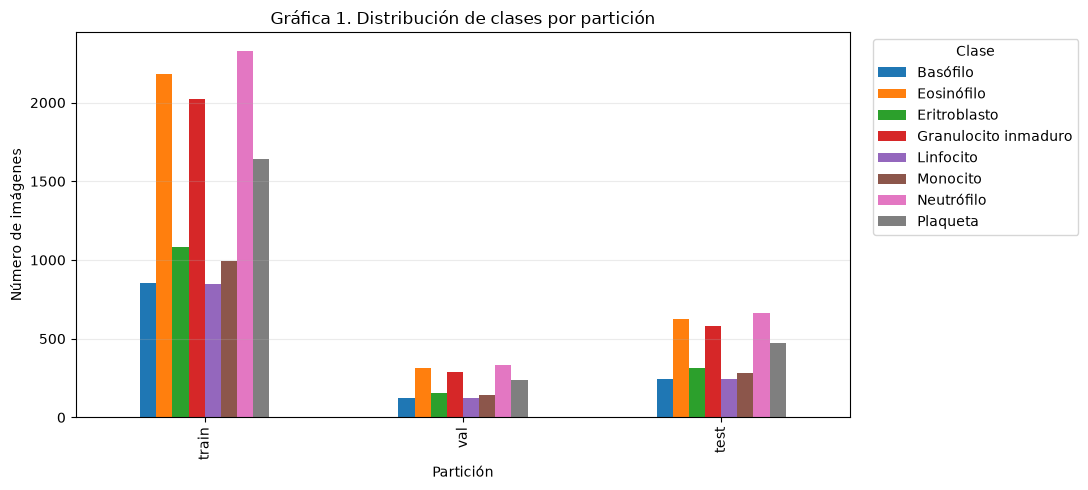

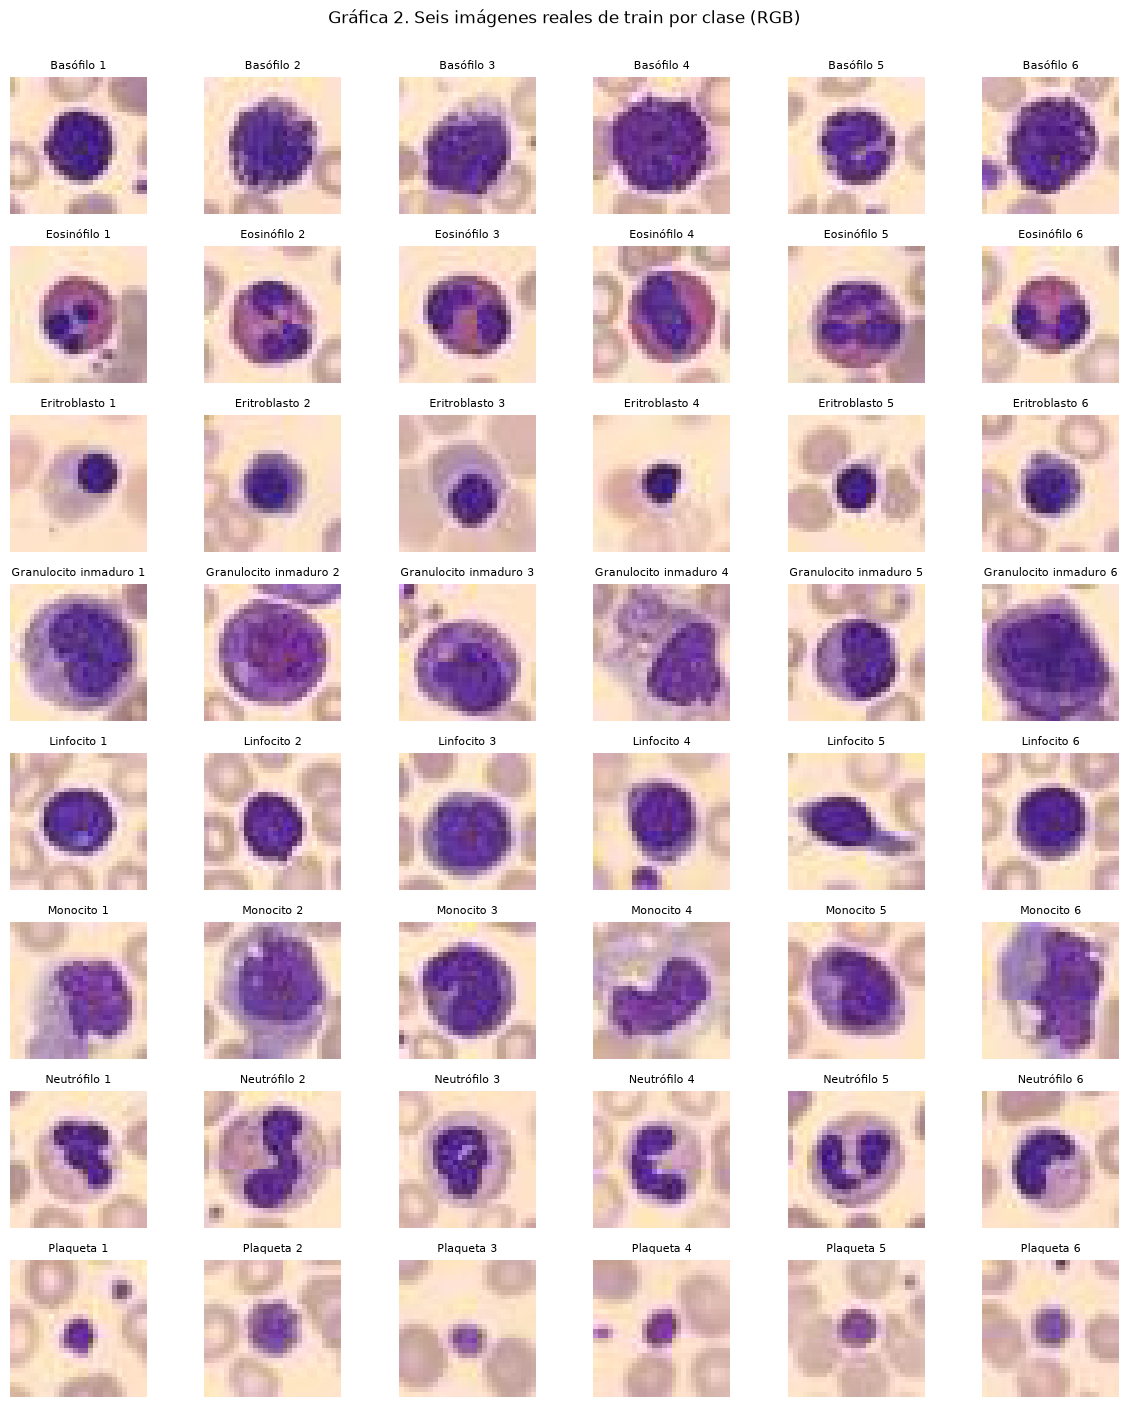

Las figuras anteriores permiten comparar visualmente las ocho clases sin modificar las imágenes ni mezclar particiones.


In [1]:
from pathlib import Path
import json
import random
import time
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score, recall_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from medmnist import BloodMNIST
from diffusers import UNet2DModel, DDPMScheduler

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python: {__import__('sys').version.split()[0]} | PyTorch: {torch.__version__}")
print(f"Dispositivo detectado: {DISPOSITIVO}")
if DISPOSITIVO.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

RAIZ = Path.cwd()
ARTEFACTOS = RAIZ / "artefactos" / "persona1"
GRAFICAS = ARTEFACTOS / "graficas"
CNN_PATH = ARTEFACTOS / "cnn_referencia.pt"
VAE_PATH = ARTEFACTOS / "vae.pt"
DDPM_DIR = ARTEFACTOS / "ddpm"
for carpeta in (ARTEFACTOS, GRAFICAS, ARTEFACTOS / "vae_imagenes", ARTEFACTOS / "ddpm_imagenes"):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES_CLASES = [
    "Basófilo", "Eosinófilo", "Eritroblasto", "Granulocito inmaduro",
    "Linfocito", "Monocito", "Neutrófilo", "Plaqueta",
]
train = BloodMNIST(split="train", download=True)
val = BloodMNIST(split="val", download=True)
test = BloodMNIST(split="test", download=True)

# Selección oficial exacta; se guarda para reproducir los índices más adelante.
idx_baso = np.where(train.labels.ravel() == 0)[0]
N = len(idx_baso)
rng = np.random.default_rng(42)
idx_sub = rng.choice(idx_baso, size=200, replace=False)
basofilos_train = train.imgs[idx_sub]
np.save(ARTEFACTOS / "idx_sub.npy", idx_sub)
assert N >= 200 and len(np.unique(idx_sub)) == 200
assert np.all(train.labels.ravel()[idx_sub] == 0)
assert basofilos_train.shape == (200, 28, 28, 3)
print(f"N = {N} basófilos en train; seleccionados = {len(idx_sub)}")
print(f"Forma seleccionada: {basofilos_train.shape}; rango RGB: [{basofilos_train.min()}, {basofilos_train.max()}]")

particiones = {"train": train, "val": val, "test": test}
conteos = pd.DataFrame(
    {nombre: np.bincount(datos.labels.ravel(), minlength=8) for nombre, datos in particiones.items()},
    index=NOMBRES_CLASES,
).T
conteos.index.name = "Partición oficial"
display(conteos)

fig, ax = plt.subplots(figsize=(11, 5))
conteos.plot(kind="bar", ax=ax)
ax.set(title="Gráfica 1. Distribución de clases por partición", xlabel="Partición", ylabel="Número de imágenes")
ax.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(8, 6, figsize=(12, 14))
for clase, ax_row in enumerate(axes):
    indices_clase = np.flatnonzero(train.labels.ravel() == clase)[:6]
    for muestra, (ax, indice) in enumerate(zip(ax_row, indices_clase), start=1):
        ax.imshow(train.imgs[indice])
        ax.set_title(f"{NOMBRES_CLASES[clase]} {muestra}", fontsize=8)
        ax.axis("off")
fig.suptitle("Gráfica 2. Seis imágenes reales de train por clase (RGB)", y=1.002)
fig.tight_layout()
fig.savefig(GRAFICAS / "muestras_reales_48.png", dpi=150, bbox_inches="tight")
plt.show()

print("Conteos de ocho clases y cuadrícula de 48 imágenes reales generados.")

### Inspección visual

En las imágenes de 28×28 observadas, los basófilos muestran principalmente un núcleo central oscuro violáceo y el detalle citoplasmático es limitado. Por su núcleo redondeado y oscuro pueden confundirse visualmente con linfocitos y algunos granulocitos inmaduros. La baja resolución y seis ejemplos por clase limitan esta apreciación.

### CNN de referencia

Las convoluciones válidas y el pooling producen mapas de 13×13 y luego 5×5; la capa densa termina en ocho logits. Estos logits son equivalentes a una salida softmax cuando se usan con `CrossEntropyLoss`, que incorpora la normalización log-softmax. Se entrena con Adam, tasa `1e-3`, hasta 10 épocas y parada temprana sobre `val_loss` (`patience=3`), restaurando el estado con menor pérdida de validación.

Época 01: train_loss=1.4110, val_loss=0.9799
Época 02: train_loss=0.8155, val_loss=0.7896
Época 03: train_loss=0.6696, val_loss=0.6599
Época 04: train_loss=0.5830, val_loss=0.6349
Época 05: train_loss=0.5473, val_loss=0.5837
Época 06: train_loss=0.5159, val_loss=0.5877
Época 07: train_loss=0.4876, val_loss=0.5538
Época 08: train_loss=0.4742, val_loss=0.5420
Época 09: train_loss=0.4452, val_loss=0.5532
Época 10: train_loss=0.4247, val_loss=0.4723


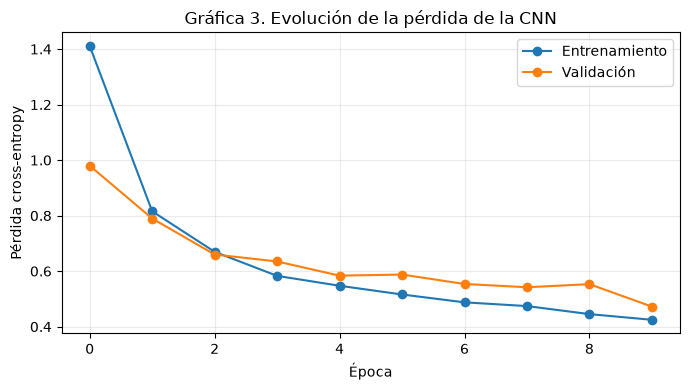

                                f1_macro  f1_basofilo  recall_basofilo  epocas  mejor_val_loss
CNN referencia en test oficial  0.769993     0.331081          0.20082      10        0.472257


CNNReferencia(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=8, bias=True)
)

In [2]:
class CNNReferencia(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 8)

    def forward(self, imagenes):
        x = self.pool(F.relu(self.conv1(imagenes)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

def cargar_cnn_referencia(ruta=CNN_PATH, device=DISPOSITIVO):
    checkpoint = torch.load(ruta, map_location="cpu", weights_only=True)
    modelo = CNNReferencia().to(device)
    modelo.load_state_dict(checkpoint["state_dict"])
    return modelo.eval(), checkpoint

def imagenes_a_tensor(imagenes, rango="cero_uno"):
    tensor = torch.as_tensor(np.asarray(imagenes), dtype=torch.float32).permute(0, 3, 1, 2)
    if rango == "cero_uno":
        tensor = tensor / 255.0
    elif rango == "menos_uno_uno":
        tensor = tensor / 127.5 - 1.0
    else:
        raise ValueError(f"Rango desconocido: {rango}")
    return tensor

labels_train = train.labels.ravel()
idx_otros = np.flatnonzero(labels_train != 0)
idx_cnn = np.concatenate((idx_sub, idx_otros))
x_cnn = imagenes_a_tensor(train.imgs[idx_cnn], "cero_uno")
y_cnn = torch.as_tensor(labels_train[idx_cnn], dtype=torch.long)
x_val = imagenes_a_tensor(val.imgs, "cero_uno")
y_val = torch.as_tensor(val.labels.ravel(), dtype=torch.long)
x_test = imagenes_a_tensor(test.imgs, "cero_uno")
y_test = torch.as_tensor(test.labels.ravel(), dtype=torch.long)
assert int((y_cnn == 0).sum()) == 200
assert len(y_cnn) == 200 + int((labels_train != 0).sum())

cnn_config = {
    "semilla": SEMILLA, "entrada": [3, 28, 28], "normalizacion": "RGB [0,255] -> [0,1]",
    "arquitectura": "Conv2d(3,32,3)-ReLU-MaxPool2d(2), Conv2d(32,64,3)-ReLU-MaxPool2d(2), Flatten, Linear(1600,128)-ReLU-Dropout(0.3), Linear(128,8) logits",
    "optimizador": "Adam", "learning_rate": 1e-3, "batch_size": 128,
    "max_epocas": 10, "early_stopping": {"monitor": "val_loss", "patience": 3, "restaurar_mejores_pesos": True},
    "n_basofilos_entrenamiento": 200, "n_otros_entrenamiento": int(len(idx_otros)),
}

if CNN_PATH.exists():
    cnn_checkpoint = torch.load(CNN_PATH, map_location="cpu", weights_only=True)
    modelo_cnn = CNNReferencia().to(DISPOSITIVO)
    modelo_cnn.load_state_dict(cnn_checkpoint["state_dict"])
    cnn_historial = cnn_checkpoint["historial"]
    epocas_cnn = cnn_checkpoint["epocas"]
    print(f"CNN recuperada de {CNN_PATH}; no se reentrena.")
else:
    torch.manual_seed(SEMILLA)
    generador_loader = torch.Generator().manual_seed(SEMILLA)
    loader_train = DataLoader(TensorDataset(x_cnn, y_cnn), batch_size=128, shuffle=True, generator=generador_loader)
    loader_val = DataLoader(TensorDataset(x_val, y_val), batch_size=256, shuffle=False)
    modelo_cnn = CNNReferencia().to(DISPOSITIVO)
    optimizador_cnn = torch.optim.Adam(modelo_cnn.parameters(), lr=1e-3)
    cnn_historial = {"train_loss": [], "val_loss": []}
    mejor_val = float("inf")
    mejores_pesos = None
    epocas_sin_mejora = 0
    for epoca in range(10):
        modelo_cnn.train()
        suma_train = 0.0
        for xb, yb in loader_train:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador_cnn.zero_grad(set_to_none=True)
            perdida = F.cross_entropy(modelo_cnn(xb), yb)
            perdida.backward()
            optimizador_cnn.step()
            suma_train += perdida.item() * len(xb)
        modelo_cnn.eval()
        suma_val = 0.0
        with torch.no_grad():
            for xb, yb in loader_val:
                xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
                suma_val += F.cross_entropy(modelo_cnn(xb), yb, reduction="sum").item()
        train_loss = suma_train / len(loader_train.dataset)
        val_loss = suma_val / len(loader_val.dataset)
        cnn_historial["train_loss"].append(train_loss)
        cnn_historial["val_loss"].append(val_loss)
        print(f"Época {epoca + 1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
        if val_loss < mejor_val:
            mejor_val = val_loss
            mejores_pesos = copy.deepcopy(modelo_cnn.state_dict())
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1
            if epocas_sin_mejora >= 3:
                print("EarlyStopping: no mejoró val_loss durante 3 épocas.")
                break
    modelo_cnn.load_state_dict(mejores_pesos)
    epocas_cnn = len(cnn_historial["train_loss"])
    torch.save({"state_dict": modelo_cnn.cpu().state_dict(), "historial": cnn_historial, "epocas": epocas_cnn, "config": cnn_config}, CNN_PATH)
    modelo_cnn.to(DISPOSITIVO)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cnn_historial["train_loss"], marker="o", label="Entrenamiento")
ax.plot(cnn_historial["val_loss"], marker="o", label="Validación")
ax.set(title="Gráfica 3. Evolución de la pérdida de la CNN", xlabel="Época", ylabel="Pérdida cross-entropy")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdida_cnn.png", dpi=150, bbox_inches="tight")
plt.show()

modelo_cnn.eval()
predicciones = []
with torch.no_grad():
    for inicio in range(0, len(x_test), 256):
        logits = modelo_cnn(x_test[inicio:inicio + 256].to(DISPOSITIVO))
        predicciones.extend(logits.argmax(dim=1).cpu().numpy().tolist())
y_test_np = y_test.numpy()
metricas_cnn = {
    "f1_macro": float(f1_score(y_test_np, predicciones, average="macro", zero_division=0)),
    "f1_basofilo": float(f1_score(y_test_np == 0, np.asarray(predicciones) == 0, zero_division=0)),
    "recall_basofilo": float(recall_score(y_test_np == 0, np.asarray(predicciones) == 0, zero_division=0)),
}
metricas_cnn.update({"epocas": epocas_cnn, "mejor_val_loss": float(min(cnn_historial["val_loss"]))})
print(pd.DataFrame([metricas_cnn], index=["CNN referencia en test oficial"]).to_string())
with open(ARTEFACTOS / "metricas_cnn.json", "w", encoding="utf-8") as archivo:
    json.dump({"metricas": metricas_cnn, "y_true": y_test_np.tolist(), "y_pred": predicciones, "historial": cnn_historial, "configuracion": cnn_config}, archivo, ensure_ascii=False, indent=2)
cnn_verificacion, _ = cargar_cnn_referencia()
with torch.no_grad():
    assert cnn_verificacion(x_test[:2].to(DISPOSITIVO)).shape == (2, 8)
print("Checkpoint CNN recargado sin reentrenar y evaluado con un lote: verificado.")
del cnn_verificacion
modelo_cnn.to("cpu")
if DISPOSITIVO.type == "cuda":
    torch.cuda.empty_cache()
modelo_cnn.to(DISPOSITIVO)

## 2.1. VAE convolucional RGB

El encoder reduce 28→14→7 y produce `mu` y `logvar` de dimensión 16; el decoder sube 7→14→28 y su salida `tanh` conserva valores en `[-1,1]`. La reconstrucción y el KL se calculan como sumas por imagen (sobre canales/píxeles y dimensión latente, respectivamente) y luego se promedian entre ejemplos del lote. La CNN usa `[0,1]`; este generador usa exclusivamente los 200 basófilos normalizados a `[-1,1]`.

VAE época 001: total=735.48, reconstrucción=726.55, KL=8.93, tiempo=0.3s
VAE época 025: total=115.96, reconstrucción=101.16, KL=14.80, tiempo=1.4s
VAE época 050: total=91.49, reconstrucción=74.08, KL=17.42, tiempo=2.4s
VAE época 075: total=78.61, reconstrucción=59.74, KL=18.88, tiempo=3.5s
VAE época 100: total=71.71, reconstrucción=51.40, KL=20.31, tiempo=4.5s
VAE época 125: total=64.52, reconstrucción=45.23, KL=19.29, tiempo=5.6s
VAE época 150: total=61.73, reconstrucción=41.07, KL=20.66, tiempo=6.6s
VAE época 175: total=57.85, reconstrucción=37.10, KL=20.74, tiempo=7.7s
VAE época 200: total=55.38, reconstrucción=35.54, KL=19.84, tiempo=8.7s
VAE época 225: total=53.94, reconstrucción=33.54, KL=20.40, tiempo=9.8s
VAE época 250: total=52.23, reconstrucción=31.51, KL=20.73, tiempo=10.9s
VAE época 275: total=50.59, reconstrucción=28.80, KL=21.79, tiempo=12.0s
VAE época 300: total=49.78, reconstrucción=28.09, KL=21.69, tiempo=13.1s
VAE finalizado: 300 épocas; entrenamiento=13.1s (GPU).


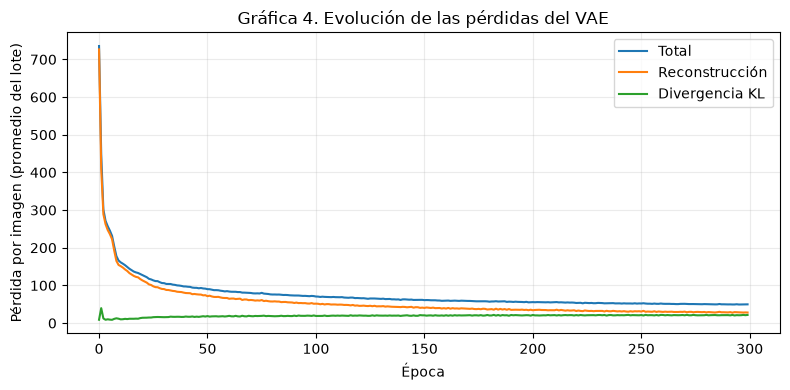

Última época: total=49.78; reconstrucción=28.09; KL=21.69


In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 64 * 7 * 7)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 3, kernel_size=3, padding=1), nn.Tanh(),
        )

    def encode(self, x):
        h = self.encoder_conv(x).flatten(start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        h = self.fc_decode(z).view(-1, 64, 7, 7)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

def perdida_vae(reconstruccion, x, mu, logvar):
    reconstruccion_por_imagen = F.mse_loss(reconstruccion, x, reduction="none").flatten(1).sum(dim=1)
    kl_por_imagen = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp(), dim=1)
    return (reconstruccion_por_imagen + kl_por_imagen).mean(), reconstruccion_por_imagen.mean(), kl_por_imagen.mean()

def guardar_vae(modelo, ruta, config, historial, segundos, epocas):
    torch.save({"state_dict": modelo.cpu().state_dict(), "config": config, "historial": historial, "tiempo_entrenamiento_segundos": segundos, "epocas": epocas}, ruta)
    modelo.to(DISPOSITIVO)

def cargar_vae(ruta=VAE_PATH, device=DISPOSITIVO):
    datos = torch.load(ruta, map_location="cpu", weights_only=True)
    modelo = VAE(latent_dim=datos["config"]["latent_dim"])
    modelo.load_state_dict(datos["state_dict"])
    return modelo.to(device).eval(), datos

vae_config = {
    "latent_dim": 16, "entrada": [3, 28, 28], "normalizacion": "RGB [0,255] -> [-1,1]",
    "encoder": "Conv2d(3,32,3,stride=2,padding=1)-ReLU; Conv2d(32,64,3,stride=2,padding=1)-ReLU; mu/logvar Linear(3136,16)",
    "decoder": "Linear(16,3136); ConvTranspose2d(64,32,4,stride=2,padding=1); ConvTranspose2d(32,16,4,stride=2,padding=1); Conv2d(16,3,3,padding=1)-tanh",
    "perdida": "media por lote de (MSE sumada por imagen + KL sumada en dimensión latente)",
    "optimizador": "Adam", "learning_rate": 1e-3, "batch_size": 32,
    "max_epocas": 300, "limite_gpu_segundos": 1200, "epocas_maximas_cpu": 30, "semilla": SEMILLA,
}
vae_historial = {"total": [], "reconstruccion": [], "kl": []}
vae_segundos = 0.0
if VAE_PATH.exists():
    modelo_vae, vae_checkpoint = cargar_vae()
    vae_historial = vae_checkpoint["historial"]
    vae_segundos = float(vae_checkpoint["tiempo_entrenamiento_segundos"])
    epocas_vae = int(vae_checkpoint["epocas"])
    print(f"VAE recuperado de {VAE_PATH}; no se reentrena.")
else:
    x_baso = imagenes_a_tensor(basofilos_train, "menos_uno_uno")
    loader_vae = DataLoader(TensorDataset(x_baso), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    torch.manual_seed(SEMILLA)
    modelo_vae = VAE(16).to(DISPOSITIVO)
    optimizador_vae = torch.optim.Adam(modelo_vae.parameters(), lr=1e-3)
    max_epocas_vae = 300 if DISPOSITIVO.type == "cuda" else 30
    inicio_vae = time.perf_counter()
    epocas_vae = 0
    for epoca in range(max_epocas_vae):
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
            if time.perf_counter() - inicio_vae >= 1200:
                break
        modelo_vae.train()
        acumulados = np.zeros(3, dtype=np.float64)
        cantidad = 0
        for (xb,) in loader_vae:
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
                if time.perf_counter() - inicio_vae >= 1200:
                    break
            xb = xb.to(DISPOSITIVO)
            optimizador_vae.zero_grad(set_to_none=True)
            reconstruccion, mu, logvar = modelo_vae(xb)
            total, recon, kl = perdida_vae(reconstruccion, xb, mu, logvar)
            total.backward()
            optimizador_vae.step()
            acumulados += np.array([total.item(), recon.item(), kl.item()]) * len(xb)
            cantidad += len(xb)
        if cantidad == 0:
            break
        for llave, valor in zip(("total", "reconstruccion", "kl"), acumulados / cantidad):
            vae_historial[llave].append(float(valor))
        epocas_vae += 1
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
        vae_segundos = time.perf_counter() - inicio_vae
        if epoca == 0 or (epoca + 1) % 25 == 0:
            print(f"VAE época {epoca + 1:03d}: total={vae_historial['total'][-1]:.2f}, reconstrucción={vae_historial['reconstruccion'][-1]:.2f}, KL={vae_historial['kl'][-1]:.2f}, tiempo={vae_segundos:.1f}s")
        guardar_vae(modelo_vae, VAE_PATH, vae_config, vae_historial, vae_segundos, epocas_vae)
        if DISPOSITIVO.type == "cuda" and vae_segundos >= 1200:
            break
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()
        vae_segundos = time.perf_counter() - inicio_vae
    guardar_vae(modelo_vae, VAE_PATH, vae_config, vae_historial, vae_segundos, epocas_vae)
    print(f"VAE finalizado: {epocas_vae} épocas; entrenamiento={vae_segundos:.1f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU, sin presupuesto GPU'}).")

fig, ax = plt.subplots(figsize=(8, 4))
for llave, etiqueta in (("total", "Total"), ("reconstruccion", "Reconstrucción"), ("kl", "Divergencia KL")):
    ax.plot(vae_historial[llave], label=etiqueta)
ax.set(title="Gráfica 4. Evolución de las pérdidas del VAE", xlabel="Época", ylabel="Pérdida por imagen (promedio del lote)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdidas_vae.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Última época: total={vae_historial['total'][-1]:.2f}; reconstrucción={vae_historial['reconstruccion'][-1]:.2f}; KL={vae_historial['kl'][-1]:.2f}")

## 2.2. DDPM con `diffusers`

La U-Net `UNet2DModel` recibe y predice tensores RGB de 28×28, con dos bloques espaciales compatibles con esta resolución. `DDPMScheduler` usa 1000 pasos de difusión para el ruido y su predicción MSE; AdamW usa `1e-4` y lote 32 (≤64). Las actualizaciones que se informan son llamadas reales a `optimizer.step()`; los 1000 pasos de difusión no son 1000 actualizaciones de parámetros. Se fijó un tope adicional de 300 épocas para acotar la ejecución, sin superar nunca los 60 minutos de GPU. Si el entorno solo ofrece CPU, se ejecutan como máximo 10 épocas y se informa como corrida parcial, sin atribuir tiempo GPU.

DDPM época 10: MSE=0.11097; actualizaciones=70; tiempo=0.1 min
DDPM época 20: MSE=0.07239; actualizaciones=140; tiempo=0.1 min
DDPM época 30: MSE=0.05218; actualizaciones=210; tiempo=0.2 min
DDPM época 40: MSE=0.06918; actualizaciones=280; tiempo=0.3 min
DDPM época 50: MSE=0.05193; actualizaciones=350; tiempo=0.3 min
DDPM época 60: MSE=0.03876; actualizaciones=420; tiempo=0.4 min
DDPM época 70: MSE=0.04288; actualizaciones=490; tiempo=0.4 min
DDPM época 80: MSE=0.03791; actualizaciones=560; tiempo=0.5 min
DDPM época 90: MSE=0.02979; actualizaciones=630; tiempo=0.6 min
DDPM época 100: MSE=0.02656; actualizaciones=700; tiempo=0.6 min
DDPM época 110: MSE=0.03932; actualizaciones=770; tiempo=0.7 min
DDPM época 120: MSE=0.03471; actualizaciones=840; tiempo=0.7 min
DDPM época 130: MSE=0.03491; actualizaciones=910; tiempo=0.8 min
DDPM época 140: MSE=0.04047; actualizaciones=980; tiempo=0.9 min
DDPM época 150: MSE=0.03184; actualizaciones=1050; tiempo=0.9 min
DDPM época 160: MSE=0.02456; actua

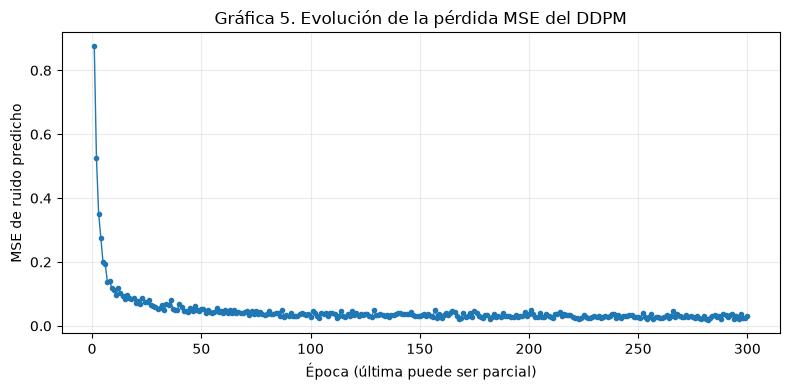

Configuración U-Net: [64, 128] canales por bloque; scheduler train timesteps=1000; batch=32; AdamW lr=1e-4.


In [4]:
ddpm_config = {
    "sample_size": 28, "in_channels": 3, "out_channels": 3,
    "layers_per_block": 1, "block_out_channels": [64, 128],
    "down_block_types": ["DownBlock2D", "AttnDownBlock2D"],
    "up_block_types": ["AttnUpBlock2D", "UpBlock2D"], "norm_num_groups": 32,
    "scheduler": "DDPMScheduler", "num_train_timesteps": 1000,
    "prediccion": "ruido añadido; pérdida MSE", "optimizador": "AdamW",
    "learning_rate": 1e-4, "batch_size": 32, "max_epocas_gpu": 300, "limite_gpu_segundos": 3600,
    "epocas_maximas_cpu": 10, "semilla": SEMILLA,
    "normalizacion": "RGB [0,255] -> [-1,1]",
}

def crear_unet(config=ddpm_config):
    return UNet2DModel(
        sample_size=config["sample_size"], in_channels=config["in_channels"], out_channels=config["out_channels"],
        layers_per_block=config["layers_per_block"], block_out_channels=tuple(config["block_out_channels"]),
        down_block_types=tuple(config["down_block_types"]), up_block_types=tuple(config["up_block_types"]),
        norm_num_groups=config["norm_num_groups"],
    )

def cargar_ddpm(ruta=DDPM_DIR, device=DISPOSITIVO):
    ruta = Path(ruta)
    modelo = UNet2DModel.from_pretrained(ruta).to(device).eval()
    scheduler = DDPMScheduler.from_pretrained(ruta / "scheduler")
    metadata = torch.load(ruta / "training_metadata.pt", map_location="cpu", weights_only=True)
    return modelo, scheduler, metadata

if DDPM_DIR.exists() and (DDPM_DIR / "training_metadata.pt").exists():
    ddpm_checkpoint = torch.load(DDPM_DIR / "training_metadata.pt", map_location="cpu", weights_only=True)
    modelo_ddpm = UNet2DModel.from_pretrained(DDPM_DIR).to(DISPOSITIVO).eval()
    ddpm_historial = ddpm_checkpoint["historial"]
    ddpm_segundos = float(ddpm_checkpoint["tiempo_entrenamiento_segundos"])
    ddpm_actualizaciones = int(ddpm_checkpoint["actualizaciones"])
    ddpm_epocas = int(ddpm_checkpoint["epocas"])
    ddpm_parcial = bool(ddpm_checkpoint["epoca_parcial"])
    print(f"DDPM recuperado de {DDPM_DIR}; no se reentrena.")
else:
    DDPM_DIR.mkdir(parents=True, exist_ok=True)
    x_baso_ddpm = imagenes_a_tensor(basofilos_train, "menos_uno_uno")
    loader_ddpm = DataLoader(TensorDataset(x_baso_ddpm), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    torch.manual_seed(SEMILLA)
    if DISPOSITIVO.type == "cuda":
        torch.cuda.manual_seed_all(SEMILLA)
    modelo_ddpm = crear_unet().to(DISPOSITIVO)
    scheduler_train = DDPMScheduler(num_train_timesteps=1000)
    scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
    optimizador_ddpm = torch.optim.AdamW(modelo_ddpm.parameters(), lr=1e-4)
    ddpm_historial = []
    ddpm_actualizaciones = 0
    ddpm_epocas = 0
    ddpm_parcial = False
    limite_segundos = 3600 if DISPOSITIVO.type == "cuda" else float("inf")
    max_epocas_ddpm = 300 if DISPOSITIVO.type == "cuda" else 10
    inicio_ddpm = time.perf_counter()
    while ddpm_epocas < max_epocas_ddpm:
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
        if time.perf_counter() - inicio_ddpm >= limite_segundos:
            break
        modelo_ddpm.train()
        suma_perdida = 0.0
        lotes_epoca = 0
        for (x0,) in loader_ddpm:
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
            if time.perf_counter() - inicio_ddpm >= limite_segundos:
                ddpm_parcial = True
                break
            x0 = x0.to(DISPOSITIVO)
            ruido = torch.randn_like(x0)
            timesteps = torch.randint(0, scheduler_train.config.num_train_timesteps, (len(x0),), device=DISPOSITIVO, dtype=torch.long)
            x_ruidoso = scheduler_train.add_noise(x0, ruido, timesteps)
            optimizador_ddpm.zero_grad(set_to_none=True)
            ruido_predicho = modelo_ddpm(x_ruidoso, timesteps).sample
            perdida = F.mse_loss(ruido_predicho, ruido)
            perdida.backward()
            optimizador_ddpm.step()
            ddpm_actualizaciones += 1
            suma_perdida += perdida.item()
            lotes_epoca += 1
        if lotes_epoca:
            ddpm_historial.append(float(suma_perdida / lotes_epoca))
            if not ddpm_parcial:
                ddpm_epocas += 1
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
            ddpm_segundos = time.perf_counter() - inicio_ddpm
            if ddpm_epocas % 10 == 0 or ddpm_parcial:
                modelo_ddpm.save_pretrained(DDPM_DIR)
                scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
                torch.save({"config": ddpm_config, "historial": ddpm_historial, "tiempo_entrenamiento_segundos": ddpm_segundos, "actualizaciones": ddpm_actualizaciones, "epocas": ddpm_epocas, "epoca_parcial": ddpm_parcial}, DDPM_DIR / "training_metadata.pt")
                print(f"DDPM época {ddpm_epocas}{' (parcial)' if ddpm_parcial else ''}: MSE={ddpm_historial[-1]:.5f}; actualizaciones={ddpm_actualizaciones}; tiempo={ddpm_segundos / 60:.1f} min")
        if ddpm_parcial or time.perf_counter() - inicio_ddpm >= limite_segundos:
            break
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()
    ddpm_segundos = time.perf_counter() - inicio_ddpm
    modelo_ddpm.save_pretrained(DDPM_DIR)
    scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
    torch.save({"config": ddpm_config, "historial": ddpm_historial, "tiempo_entrenamiento_segundos": ddpm_segundos, "actualizaciones": ddpm_actualizaciones, "epocas": ddpm_epocas, "epoca_parcial": ddpm_parcial}, DDPM_DIR / "training_metadata.pt")
    print(f"DDPM finalizado: {ddpm_epocas} épocas completas; parcial={ddpm_parcial}; actualizaciones reales={ddpm_actualizaciones}; entrenamiento={ddpm_segundos:.1f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU, sin presupuesto GPU'}).")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(ddpm_historial) + 1), ddpm_historial, marker=".", linewidth=1)
ax.set(title="Gráfica 5. Evolución de la pérdida MSE del DDPM", xlabel="Época (última puede ser parcial)", ylabel="MSE de ruido predicho")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdida_ddpm.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Configuración U-Net: {ddpm_config['block_out_channels']} canales por bloque; scheduler train timesteps={scheduler_train.config.num_train_timesteps if 'scheduler_train' in globals() else 1000}; batch=32; AdamW lr=1e-4.")

## 2.3. Generación y conservación

Se generan exactamente 300 imágenes nuevas por modelo. Para DDPM se usan 50 pasos de inferencia, independientes de los 1000 pasos del scheduler de entrenamiento. Los tiempos se miden por separado para el muestreo de cada lote y se sincroniza CUDA si existe. Después se convierten los tensores RGB `[-1,1]` a PNG RGB de 28×28 y se verifican forma, modo y cantidad. Las funciones permiten solicitar cualquier cantidad de muestras para las actividades posteriores.

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


VAE: 300 PNG RGB 28x28 verificados en c:\Users\danie\Documents2\Analisis-con-Deep-learning\Taller 4\artefactos\persona1\vae_imagenes
DDPM: 300 PNG RGB 28x28 verificados en c:\Users\danie\Documents2\Analisis-con-Deep-learning\Taller 4\artefactos\persona1\ddpm_imagenes


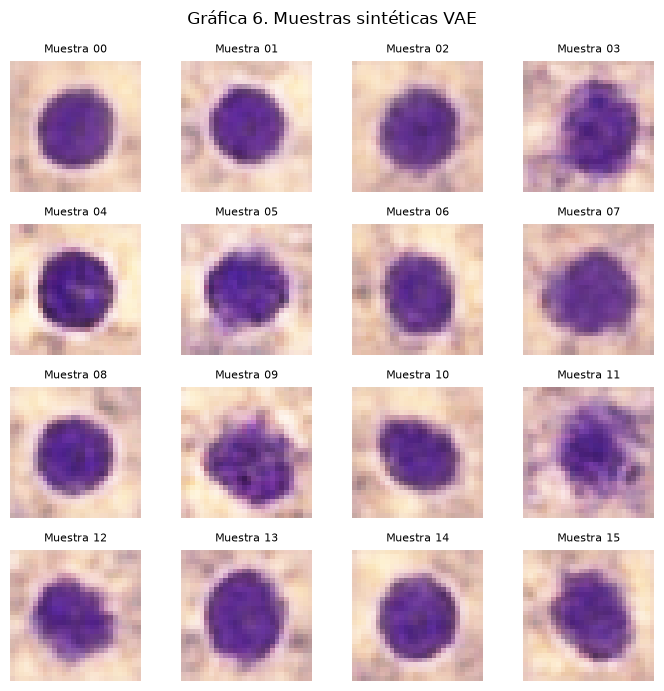

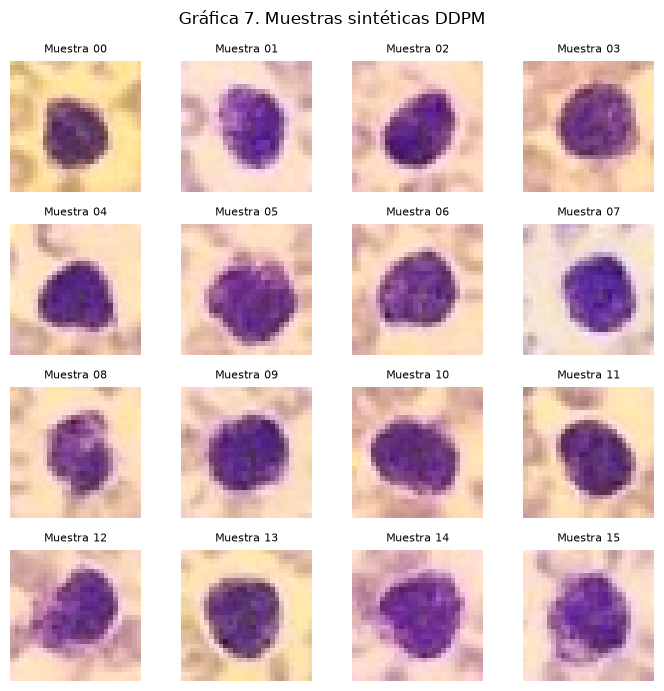

Carga de checkpoints sin reentrenar y generación reutilizable de 2 imágenes por modelo: verificados.
Generación VAE: 300 imágenes en 0.02s (muestreo; GPU).
Generación DDPM: 300 imágenes, 50 pasos de inferencia, en 12.49s (muestreo; GPU).


,Modelo,Épocas,Pérdida final,Tiempo entrenamiento (s),Actualizaciones
0,CNN referencia,10,0.472257,NaN,NaN
1,VAE,300,49.780727,13.072183,NaN
2,DDPM,300,0.030810,112.036502,2100.0


Entrega escrita: c:\Users\danie\Documents2\Analisis-con-Deep-learning\Taller 4\artefactos\persona1\ENTREGA_PERSONA1.md
Índices seleccionados: c:\Users\danie\Documents2\Analisis-con-Deep-learning\Taller 4\artefactos\persona1\idx_sub.npy; configuración: c:\Users\danie\Documents2\Analisis-con-Deep-learning\Taller 4\artefactos\persona1\configuracion.json


In [5]:
def sincronizar_si_cuda(device=DISPOSITIVO):
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def generar_vae(modelo, cantidad, batch_size=64, seed=123, device=DISPOSITIVO):
    modelo = modelo.to(device).eval()
    generador = torch.Generator(device=device).manual_seed(seed)
    lotes = []
    for inicio in range(0, cantidad, batch_size):
        n_lote = min(batch_size, cantidad - inicio)
        z = torch.randn(n_lote, modelo.latent_dim, generator=generador, device=device)
        with torch.no_grad():
            lotes.append(modelo.decode(z).cpu())
    return torch.cat(lotes) if lotes else torch.empty((0, 3, 28, 28))

def generar_ddpm(modelo, cantidad, pasos_inferencia=50, batch_size=16, seed=456, device=DISPOSITIVO, scheduler=None):
    modelo = modelo.to(device).eval()
    scheduler = copy.deepcopy(scheduler) if scheduler is not None else DDPMScheduler.from_pretrained(DDPM_DIR / "scheduler")
    scheduler.set_timesteps(pasos_inferencia, device=device)
    generador = torch.Generator(device=device).manual_seed(seed)
    lotes = []
    for inicio in range(0, cantidad, batch_size):
        n_lote = min(batch_size, cantidad - inicio)
        x = torch.randn((n_lote, 3, 28, 28), generator=generador, device=device)
        with torch.no_grad():
            for timestep in scheduler.timesteps:
                prediccion = modelo(x, timestep).sample
                x = scheduler.step(prediccion, timestep, x, generator=generador).prev_sample
        lotes.append(x.clamp(-1, 1).cpu())
    return torch.cat(lotes) if lotes else torch.empty((0, 3, 28, 28))

def guardar_png_rgb(tensores, carpeta):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    datos = ((tensores.detach().cpu().clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1).numpy()
    for indice, imagen in enumerate(datos):
        Image.fromarray(imagen).save(carpeta / f"{indice:03d}.png", format="PNG")

def mostrar_cuadricula(tensores, titulo, nombre_archivo):
    cantidad = min(16, len(tensores))
    fig, axes = plt.subplots(4, 4, figsize=(7, 7))
    for indice, ax in enumerate(axes.flat):
        if indice < cantidad:
            imagen = ((tensores[indice].clamp(-1, 1) + 1) / 2).permute(1, 2, 0).numpy()
            ax.imshow(imagen)
            ax.set_title(f"Muestra {indice:02d}", fontsize=8)
        ax.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(GRAFICAS / nombre_archivo, dpi=150, bbox_inches="tight")
    plt.show()

modelo_vae, vae_checkpoint = cargar_vae()
modelo_ddpm, scheduler_ddpm, ddpm_checkpoint = cargar_ddpm()
PASOS_INFERENCIA_DDPM = 50
if DISPOSITIVO.type == "cuda":
    sincronizar_si_cuda()
inicio = time.perf_counter()
imagenes_vae = generar_vae(modelo_vae, 300, batch_size=64, seed=1001)
sincronizar_si_cuda()
tiempo_generacion_vae = time.perf_counter() - inicio
guardar_png_rgb(imagenes_vae, ARTEFACTOS / "vae_imagenes")

if DISPOSITIVO.type == "cuda":
    sincronizar_si_cuda()
inicio = time.perf_counter()
imagenes_ddpm = generar_ddpm(modelo_ddpm, 300, pasos_inferencia=PASOS_INFERENCIA_DDPM, batch_size=16, seed=1002, scheduler=scheduler_ddpm)
sincronizar_si_cuda()
tiempo_generacion_ddpm = time.perf_counter() - inicio
guardar_png_rgb(imagenes_ddpm, ARTEFACTOS / "ddpm_imagenes")

for nombre, carpeta in (("VAE", ARTEFACTOS / "vae_imagenes"), ("DDPM", ARTEFACTOS / "ddpm_imagenes")):
    archivos = sorted(carpeta.glob("*.png"))
    assert len(archivos) == 300, f"{nombre}: se esperaban 300 PNG y hay {len(archivos)}"
    assert archivos[0].name == "000.png" and archivos[-1].name == "299.png"
    for ruta in archivos:
        with Image.open(ruta) as imagen:
            assert imagen.size == (28, 28) and imagen.mode == "RGB", f"Archivo no RGB 28x28: {ruta}"
    print(f"{nombre}: {len(archivos)} PNG RGB 28x28 verificados en {carpeta}")

mostrar_cuadricula(imagenes_vae, "Gráfica 6. Muestras sintéticas VAE", "muestras_vae.png")
mostrar_cuadricula(imagenes_ddpm, "Gráfica 7. Muestras sintéticas DDPM", "muestras_ddpm.png")
assert len(generar_vae(modelo_vae, 2, seed=2001)) == 2
assert len(generar_ddpm(modelo_ddpm, 2, pasos_inferencia=PASOS_INFERENCIA_DDPM, seed=2002, scheduler=scheduler_ddpm)) == 2
print("Carga de checkpoints sin reentrenar y generación reutilizable de 2 imágenes por modelo: verificados.")
print(f"Generación VAE: 300 imágenes en {tiempo_generacion_vae:.2f}s (muestreo; {'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}).")
print(f"Generación DDPM: 300 imágenes, {PASOS_INFERENCIA_DDPM} pasos de inferencia, en {tiempo_generacion_ddpm:.2f}s (muestreo; {'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}).")

configuracion_final = {
    "semilla": SEMILLA, "N": int(N), "idx_sub": "idx_sub.npy",
    "clases": NOMBRES_CLASES, "forma_rgb": [28, 28, 3], "rango_imagen_original": [0, 255],
    "cnn": {**cnn_config, "metricas_test": metricas_cnn, "historial": cnn_historial, "checkpoint": str(CNN_PATH.relative_to(RAIZ))},
    "vae": {**vae_config, "epocas_realizadas": epocas_vae, "historial_final": {k: v[-1] for k, v in vae_historial.items()}, "tiempo_entrenamiento_segundos": vae_segundos, "checkpoint": str(VAE_PATH.relative_to(RAIZ)), "imagenes": "artefactos/persona1/vae_imagenes/000.png..299.png", "tiempo_generacion_300_segundos": tiempo_generacion_vae},
    "ddpm": {**ddpm_config, "epocas_completas": ddpm_epocas, "epoca_parcial": ddpm_parcial, "perdida_final": ddpm_historial[-1], "historial": ddpm_historial, "actualizaciones_reales": ddpm_actualizaciones, "tiempo_entrenamiento_segundos": ddpm_segundos, "pasos_inferencia": PASOS_INFERENCIA_DDPM, "checkpoint": "artefactos/persona1/ddpm/", "imagenes": "artefactos/persona1/ddpm_imagenes/000.png..299.png", "tiempo_generacion_300_segundos": tiempo_generacion_ddpm},
    "particiones": {k: "MedMNIST BloodMNIST split oficial" for k in particiones},
    "dispositivo": str(DISPOSITIVO), "python": __import__("sys").version.split()[0],
    "versiones": {"torch": torch.__version__, "medmnist": __import__("medmnist").__version__, "diffusers": __import__("diffusers").__version__},
}
with open(ARTEFACTOS / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_final, archivo, ensure_ascii=False, indent=2)

tabla_resumen = pd.DataFrame([
    {"Modelo": "CNN referencia", "Épocas": epocas_cnn, "Pérdida final": cnn_historial["val_loss"][-1], "Tiempo entrenamiento (s)": None, "Actualizaciones": None},
    {"Modelo": "VAE", "Épocas": epocas_vae, "Pérdida final": vae_historial["total"][-1], "Tiempo entrenamiento (s)": vae_segundos, "Actualizaciones": None},
    {"Modelo": "DDPM", "Épocas": ddpm_epocas, "Pérdida final": ddpm_historial[-1], "Tiempo entrenamiento (s)": ddpm_segundos, "Actualizaciones": ddpm_actualizaciones},
])
display(tabla_resumen)

lineas_entrega = [
    "# Entrega persona 1 — Taller 4", "",
    "## Estado", "",
    "Completadas: actividad 1 (exploración y CNN de referencia), actividad 2.1 (VAE), actividad 2.2 (DDPM) y actividad 2.3 (300 PNG por generador). Las actividades 3, 4, 5 y el bono GAN quedan explícitamente para la persona 2.", "",
    f"Dispositivo de ejecución: {DISPOSITIVO}" + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO.type == "cuda" else " (sin GPU utilizable; los límites de GPU no se consumieron)."),
    f"Python {__import__('sys').version.split()[0]}; PyTorch {torch.__version__}; MedMNIST {__import__('medmnist').__version__}; diffusers {__import__('diffusers').__version__}.", "",
    "## Datos y CNN de referencia", "",
    f"BloodMNIST oficial: N={N} basófilos en train; índices únicos seleccionados con `default_rng(42)`: 200. Conteos train: `{conteos.loc['train'].to_dict()}`; val: `{conteos.loc['val'].to_dict()}`; test: `{conteos.loc['test'].to_dict()}`.",
    f"CNN: {epocas_cnn} épocas, mejor val_loss={metricas_cnn['mejor_val_loss']:.6f}; test F1 macro={metricas_cnn['f1_macro']:.6f}, F1 basófilo={metricas_cnn['f1_basofilo']:.6f}, recall basófilo={metricas_cnn['recall_basofilo']:.6f}.",
    "Entrada CNN RGB en [0,1]. Checkpoint: `artefactos/persona1/cnn_referencia.pt`; métricas, `y_true`, `y_pred` e historial: `artefactos/persona1/metricas_cnn.json`.",
    "El archivo `idx_sub.npy` contiene las posiciones dentro de `train`; los 200 basófilos originales se reconstruyen con `train.imgs[np.load(ARTEFACTOS / 'idx_sub.npy')]`. Recuperar N: `int((train.labels.ravel() == 0).sum())`. La persona 2 puede reusar `CNNReferencia` del notebook y cargar `state_dict` del checkpoint; sus datos sintéticos deben convertirse con el mismo `imagenes_a_tensor(..., 'cero_uno')`.", "",
    "## Generadores", "",
    f"VAE: latent_dim=16, Adam lr=1e-3, batch=32, {epocas_vae} épocas; pérdidas finales total={vae_historial['total'][-1]:.6f}, reconstrucción={vae_historial['reconstruccion'][-1]:.6f}, KL={vae_historial['kl'][-1]:.6f}; entrenamiento {vae_segundos:.2f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}). Checkpoint: `artefactos/persona1/vae.pt`.",
    f"DDPM: UNet2DModel canales {ddpm_config['block_out_channels']}, DDPMScheduler train=1000, AdamW lr=1e-4, batch=32; {ddpm_epocas} épocas completas, parcial={ddpm_parcial}, {ddpm_actualizaciones} actualizaciones; MSE final={ddpm_historial[-1]:.6f}; entrenamiento {ddpm_segundos:.2f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}). Checkpoint y configuración: `artefactos/persona1/ddpm/`.",
    f"Los generadores reciben RGB `[0,255] -> [-1,1]`; al guardar se mapea a PNG RGB `[0,255]`. VAE 300 imágenes: `artefactos/persona1/vae_imagenes/`; DDPM 300 imágenes: `artefactos/persona1/ddpm_imagenes/`, inferencia={PASOS_INFERENCIA_DDPM} pasos. Tiempo de muestreo de 300: VAE {tiempo_generacion_vae:.2f}s; DDPM {tiempo_generacion_ddpm:.2f}s.",
    "Funciones para generar cantidades arbitrarias: `generar_vae(modelo, cantidad, ...)` y `generar_ddpm(modelo, cantidad, pasos_inferencia=50, scheduler=scheduler_ddpm)`. Carga VAE: `modelo_vae, vae_checkpoint = cargar_vae()`. Carga DDPM sin reentrenar: `modelo_ddpm, scheduler_ddpm, metadata = cargar_ddpm()`. Carga CNN: `modelo_cnn, checkpoint = cargar_cnn_referencia()`.", "",
    "## Continuación de la persona 2", "",
    "Al reabrir el notebook, ejecutar hasta las celdas que definen las clases y funciones de carga; el código detecta checkpoints y no vuelve a entrenar. Para la actividad 3, inspeccionar 16 muestras y comparar las 300 imágenes con test usando los procedimientos del enunciado. Para la actividad 4, `N-200` imágenes sintéticas se pueden pedir al generador elegido mediante `generar_vae` o `generar_ddpm`; reconstruir las imágenes de train y test desde `BloodMNIST(split=..., download=True)`, conservar particiones oficiales y evaluar las tres CNN. La persona 2 debe ejecutar por separado las actividades 3, 4 y 5: aquí no se calcularon distancias/diversidad/memorización, no se eligió generador ni se entrenaron las dos CNN comparativas.", "",
    "## Reproducción, fuentes y limitaciones", "",
    "Entorno usado: Python 3.13.2 y el `.venv` del repositorio. Activar en PowerShell: `.venv\\Scripts\\Activate.ps1`. Instalar PyTorch para CUDA desde la instrucción oficial compatible con el driver/GPU y después `python -m pip install diffusers medmnist numpy pandas matplotlib scikit-learn pillow ipykernel jupyter nbformat nbconvert`. Abrir `Taller 4/juan_alvarez_daniel_ortiz.ipynb` en VS Code, seleccionar `.venv` como kernel y ejecutar de arriba abajo. MedMNIST descarga BloodMNIST a su caché de usuario; no se copia el dataset al repositorio.",
    "MedMNIST informa que BloodMNIST está bajo CC BY 4.0 (dataset); citar Yang et al., *MedMNIST v2: A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification*, Scientific Data 10, 41 (2023), doi:10.1038/s41597-022-01721-8, y también Yang, Shi & Ni, ISBI 2021, doi:10.1109/ISBI48211.2021.9434062. La licencia del código MedMNIST es Apache-2.0 y es distinta de la licencia de los datos. DDPM se implementó con Hugging Face Diffusers; citar Ho et al., *Denoising Diffusion Probabilistic Models* (NeurIPS 2020) y la documentación de diffusers. BloodMNIST y estos resultados son académicos; no son para uso clínico.",
    "Fuentes oficiales: https://medmnist.com/ ; https://github.com/MedMNIST/MedMNIST ; https://doi.org/10.5281/zenodo.10519652 ; https://huggingface.co/docs/diffusers/ ; https://arxiv.org/abs/2006.11239 .", "",
    "## Visual inspection", "",
    "The grids of 48 real images and synthetic samples are saved in `artefactos/persona1/graficas/`. Both generators produced cell-like purple central regions; the VAE samples look smoother, while the DDPM samples show somewhat more variation but remain low-resolution with soft edges and limited detail. This is a visual check only, not the formal evaluation in activity 3.",
    ]
(ARTEFACTOS / "ENTREGA_PERSONA1.md").write_text("\n".join(lineas_entrega) + "\n", encoding="utf-8")
print(f"Entrega escrita: {ARTEFACTOS / 'ENTREGA_PERSONA1.md'}")
print(f"Índices seleccionados: {ARTEFACTOS / 'idx_sub.npy'}; configuración: {ARTEFACTOS / 'configuracion.json'}")


### Resultados observados y limitaciones

La CNN de referencia obtuvo en el test oficial F1 macro **0.769993**, F1 de bas?filo **0.331081** y recall de bas?filo **0.200820**. El desempe?o por clase es desigual: el F1 macro resume las ocho clases, mientras que las m?tricas de bas?filo son m?s bajas con solo 200 ejemplos de esa clase en entrenamiento. Estos son resultados de una ?nica semilla, no una comparaci?n de los generadores ni evidencia cl?nica.

El VAE complet? 300 ?pocas en **13.07 s de GPU**; sus p?rdidas finales por imagen fueron total **49.7807**, reconstrucci?n **28.0898** y KL **21.6909**. El DDPM complet? 300 ?pocas y **2,100 actualizaciones reales** en **112.04 s de GPU**, con MSE final **0.030810**. Sus 1,000 pasos describen el scheduler de entrenamiento; para las 300 im?genes se usaron **50 pasos de inferencia**. Los tiempos separados de generaci?n fueron **0.02 s** para el VAE y **12.49 s** para DDPM.

En las cuadr?culas de muestra, ambos modelos producen regiones centrales viol?ceas con aspecto celular, pero los bordes y detalles finos son suaves y poco definidos a 28?28. En estas 16 muestras el VAE se ve m?s suavizado; DDPM presenta algo m?s de variaci?n de forma y textura, aunque tambi?n mantiene contornos suaves. Esta observaci?n es descriptiva y no sustituye la comparaci?n formal de calidad, diversidad o memorizaci?n, reservada a la persona 2.

### Referencias académicas y licencia

BloodMNIST/MedMNIST se distribuye bajo **CC BY 4.0** (la licencia Apache-2.0 del repositorio corresponde al código, no a las imágenes). Citar: Yang, J. et al. (2023), “MedMNIST v2: A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification”, *Scientific Data*, 10, 41. https://doi.org/10.1038/s41597-022-01721-8; y Yang, J., Shi, R. & Ni, B. (2021), “MedMNIST Classification Decathlon: A Lightweight AutoML Benchmark for Medical Image Analysis”, ISBI. https://doi.org/10.1109/ISBI48211.2021.9434062. Dataset oficial y licencia: https://doi.org/10.5281/zenodo.10519652.

La implementación del DDPM usa Hugging Face `diffusers` y sus clases `UNet2DModel` y `DDPMScheduler` (https://huggingface.co/docs/diffusers/); referencia del proceso: Ho, J., Jain, A. & Abbeel, P. (2020), “Denoising Diffusion Probabilistic Models”, NeurIPS. https://arxiv.org/abs/2006.11239. Estas evaluaciones son académicas; BloodMNIST no está destinado al uso clínico.